In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# Better data generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    r"C:\Users\Prince\Downloads\archive (1)\training_set\training_set",
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    r"C:\Users\Prince\Downloads\archive (1)\test_set\test_set",
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)


Found 8005 images belonging to 2 classes.
Found 2023 images belonging to 2 classes.


In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
model.fit(train_generator, validation_data=test_generator, epochs=24,callbacks=EarlyStopping())

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# 🔁 Change to 'cat.jpg' or 'dog.jpg'
img_path = r"C:\Users\Prince\Downloads\1022_1.jpg"

# Load and preprocess
img = image.load_img(img_path, target_size=(150, 150))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array /= 255.0

# Predict
prediction = model.predict(img_array)

# Result
if prediction[0][0] > 0.5:
    print("🐶 It's a **Dog** with {:.2f}% confidence.".format(prediction[0][0] * 100))
else:
    print("🐱 It's a **Cat** with {:.2f}% confidence.".format((1 - prediction[0][0]) * 100))

# Show image
plt.imshow(img)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [ ]:
#model.save("cat_dog_model.keras")

import os
print(os.getcwd())

In [22]:
print(train_generator.class_indices)

{'cats': 0, 'dogs': 1}


In [1]:
from tensorflow.keras.models import load_model
model = load_model('cat_dog_model.keras')

In [16]:
history = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=20
)

Epoch 1/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 124s 487ms/step - accuracy: 0.6264 - loss: 0.6454 - val_accuracy: 0.6911 - val_loss: 0.6071
Epoch 2/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 120s 476ms/step - accuracy: 0.6592 - loss: 0.6223 - val_accuracy: 0.6752 - val_loss: 0.5974
Epoch 3/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 122s 486ms/step - accuracy: 0.6746 - loss: 0.6054 - val_accuracy: 0.7064 - val_loss: 0.5658
Epoch 4/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 124s 494ms/step - accuracy: 0.6856 - loss: 0.5861 - val_accuracy: 0.7341 - val_loss: 0.5382
Epoch 5/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 122s 484ms/step - accuracy: 0.6999 - loss: 0.5794 - val_accuracy: 0.7163 - val_loss: 0.5650
Epoch 6/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 120s 479ms/step - accuracy: 0.7118 - loss: 0.5594 - val_accuracy: 0.7252 - val_loss: 0.5501
Epoch 7/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 122s 488ms/step - accuracy: 0.7208 - loss: 0.5452 - val_accuracy: 0.7375 - val_loss: 0.5234
Epoch 8/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 124s 492ms/step - accuracy: 0.7303 -

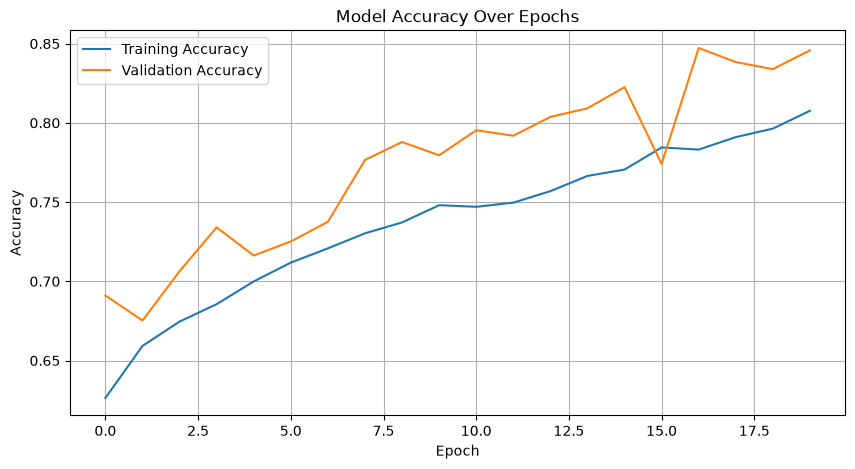

In [17]:
import matplotlib.pyplot as plt

# Get training history
history = model.history.history

# Plot Accuracy
plt.figure(figsize=(10, 5))
plt.plot(history['accuracy'], label='Training Accuracy')
plt.plot(history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

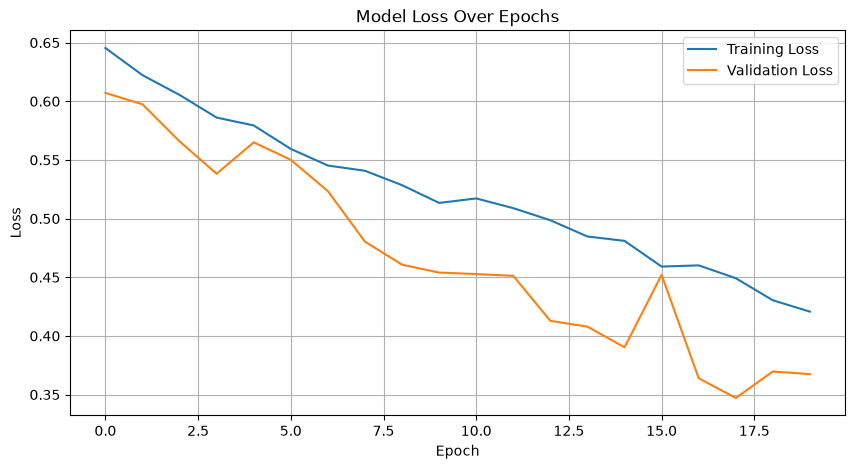

In [18]:
# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [19]:
acc = history['accuracy']
val_acc = history['val_accuracy']

loss = history['loss']
val_loss = history['val_loss']

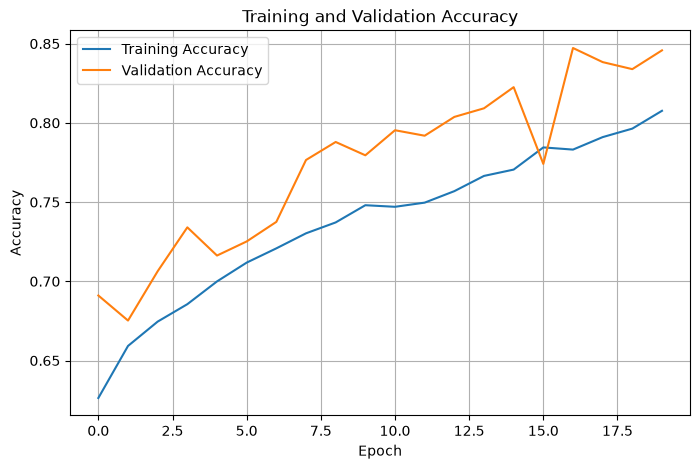

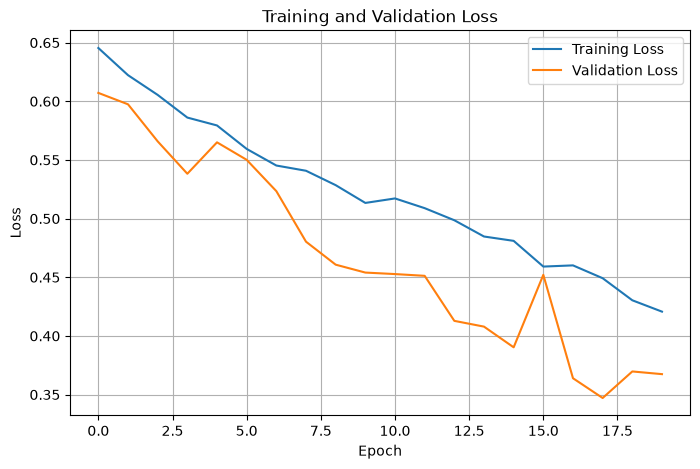

In [20]:
import matplotlib.pyplot as plt

# Plot Accuracy
plt.figure(figsize=(8, 5))
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot Loss
plt.figure(figsize=(8, 5))
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()
